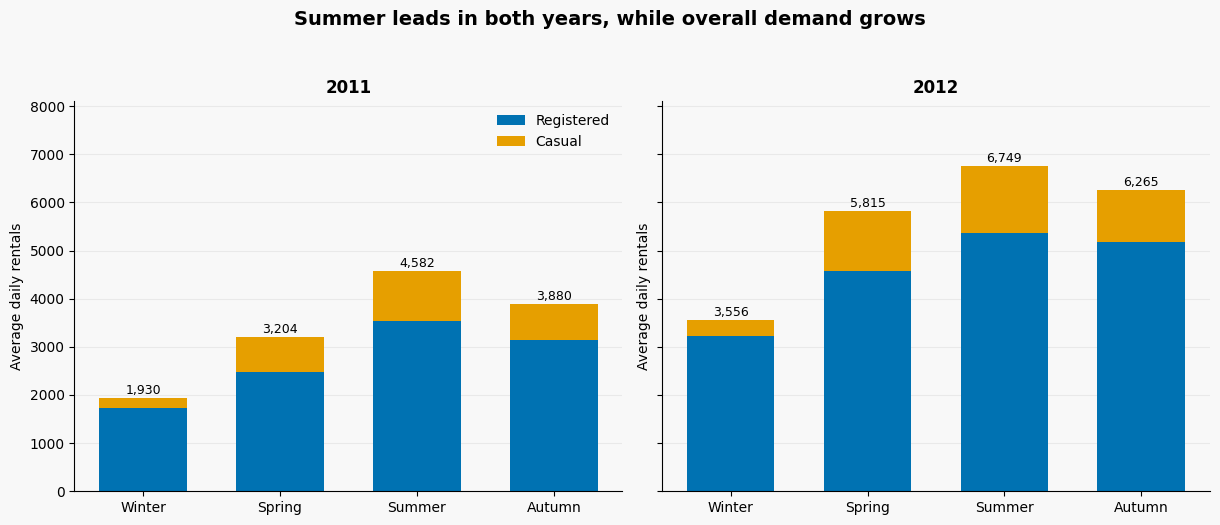

registered  casual     cnt
year season_name                            
2011 Autumn           3139.9   740.2  3880.2
     Spring           2483.8   719.8  3203.7
     Summer           3539.5  1042.5  4582.0
     Winter           1732.9   197.4  1930.3
2012 Autumn           5173.1  1091.5  6264.6
     Spring           4572.3  1242.5  5814.8
     Summer           5355.9  1393.4  6749.3
     Winter           3216.0   339.9  3556.0

In [1]:
# Noleggi nelle quattro stagioni

# Importiamo le librerie e definiamo i colori degli utenti.
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

MUTED = '#647280'
REGISTERED = '#0072B2'
CASUAL = '#E69F00'
plt.rcParams['figure.facecolor'] = '#F8F8F8'
plt.rcParams['axes.facecolor'] = '#F8F8F8'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Apriamo i dati giornalieri e ricaviamo l’anno.
day=pd.read_csv('../data/processed/bike_day_clean.csv')
day['dteday']=pd.to_datetime(day['dteday'])
day['year']=day['dteday'].dt.year

# Associamo ogni mese alla sua stagione meteorologica.
seasons={12:'Winter',1:'Winter',2:'Winter',3:'Spring',4:'Spring',5:'Spring',
         6:'Summer',7:'Summer',8:'Summer',9:'Autumn',10:'Autumn',11:'Autumn'}
day['season_name']=day['dteday'].dt.month.map(seasons)
order=['Winter','Spring','Summer','Autumn']

# Calcoliamo i noleggi medi al giorno per stagione e anno.
summary=(day.groupby(['year','season_name'])[['registered','casual','cnt']]
         .mean().round(1))

# Confrontiamo 2011 e 2012 su due pannelli con la stessa scala.
fig,axes=plt.subplots(1,2,figsize=(12.3,5),sharey=True)

# Disegniamo barre impilate per registrati e occasionali.
for ax,year in zip(axes,[2011,2012]):
    v=summary.loc[year].reindex(order)
    positions=range(4)
    ax.bar(positions,v['registered'],label='Registered',color=REGISTERED,width=.64)
    ax.bar(positions,v['casual'],bottom=v['registered'],label='Casual',
           color=CASUAL,width=.64)
    for i,total in enumerate(v['cnt']):
        ax.text(i,total+85,f'{total:,.0f}',ha='center',fontsize=9)
    ax.set_xticks(list(positions),order)
    ax.set_title(str(year),fontweight='bold')
    ax.set_ylabel('Average daily rentals')
    ax.grid(axis='y', alpha=0.2); ax.set_axisbelow(True)
    ax.set_ylim(0, summary['cnt'].max()*1.20)
axes[0].legend(frameon=False)

# Aggiungiamo un titolo informativo e salviamo il grafico.
fig.suptitle('Summer leads in both years, while overall demand grows',
             fontsize=14,fontweight='bold',y=1.04)
fig.tight_layout()
Path('../output/figures').mkdir(parents=True,exist_ok=True)
fig.savefig('../output/figures/RQ5_seasons_by_year.png',dpi=200,bbox_inches='tight')
plt.show()

# Mostriamo anche la tabella numerica delle medie.
display(summary)